# TCGA (BRCA, LIHC, COAD): cell-line weights of the 64 weighted LINCS lines

Weights of the weighted sRGES (wsRGES) for the three TCGA cancers of the Chen 2017 ChEMBL IC50 validation. The 58 LINCS lines with
DepMap expression are weighted from DepMap; six LINCS lines without DepMap expression are weighted from external RNA-seq profiles
(HPA cell lines; GEO GSE144279 for NPC and NEU), as in the case studies. This notebook shows where the six lines fall among the
weighted lines and checks that the external and DepMap weights are on the same scale.

## Definitions

| Term | What it is | Where computed |
|---|---|---|
| **Tumour samples** | TCGA primary-tumour samples (barcode sample code 01) of the cancer; GDC STAR log2(TPM + 1), UCSC Xena GDC hub. | `tcga_ccle_cell_line_weights.load_tumours` |
| **Marker genes** | The 5,000 genes with the largest interquartile range across the 1,673 CCLE lines with DepMap expression (`binchen2017_iqr5000`); the genes present in a profile are used (4,958 for HPA, 4,902 for GEO). | `cell_line_similarity.marker_genes` |
| **Weight** (`cor`) | Median, over the tumour samples, of the Spearman correlation between a tumour sample and the line's profile over the marker genes (dimensionless, -1 to 1). | `tcga_ccle_cell_line_weights.py` |
| **Normalised weight** | `cor / max(cor)` over the weighted lines of the cancer, the factor applied to every CS of the line in the wsRGES. | `sRGES.compute_sRGES` |
| **Source** | `DepMap` (DepMap 24Q4 log2(TPM + 1)); `HPA <line>, <match>` (HPA cell-line log2(TPM + 1)); `GEO <profile>, <match>` (GEO counts turned into TPM, mean of the wild-type samples). `<match>` = how close the profile is to the LINCS line: same line, parent line, same cell type, or same donor iPSC with external differentiation. | `cell_line_similarity.EXTERNAL_PROFILES`, `GEO_PROFILES` |
| **Paired lines** | DepMap lines with expression that also have an HPA profile (match on the stripped line name); each is weighted from both sources. | `tcga_ccle_cell_line_weights.external_weights` |
| **Percentile among CCLE** | Percentage of the CCLE lines with DepMap expression whose weight is below the line's weight (0-100). | same |
| **Rank among LINCS** | Rank of the weight among the 64 weighted LINCS lines of the cancer (1 = most similar). | same |
| **Validation line** | The line whose ChEMBL IC50 values are correlated with the drug scores: MCF7 (BRCA), HepG2 (LIHC), HT29 (COAD). | `wsRGES_IC50_correlations.CANCERS` |


In [1]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path(os.getcwd()).resolve()
while not (ROOT / 'connectivity_score' / 'input').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import conf
import lfs_style
lfs_style.apply()
OUT = conf.BINCHEN_VALIDATION_OUT_DIR
IMG = conf.IMG_DIR / 'binchen2017_validation'
IMG.mkdir(parents=True, exist_ok=True)
REL = '../imgs/binchen2017_validation'      # image path relative to this notebook
CANCERS = {'BRCA': 'MCF7', 'LIHC': 'HEPG2', 'COAD': 'HT29'}
CASES = ['asthma_GSE152004', 'ipf', 'als_NYGC']
def md(df, index=True, fmt='{:.3f}'):
    df = df.reset_index() if index else df
    def f(v):
        if isinstance(v, (float, np.floating)):
            return '' if np.isnan(v) else (fmt.format(v) if not float(v).is_integer() or abs(v) < 1 else f'{v:.0f}')
        return str(v)
    lines = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)]
    lines += ['| ' + ' | '.join(f(v) for v in r) + ' |' for r in df.itertuples(index=False)]
    display(Markdown(chr(10).join(lines)))

w = pd.read_csv(OUT / 'tcga_cell_line_weights.tsv', sep='\t')
w58 = pd.read_csv(OUT / 'tcga_cell_line_weights_ccle58.tsv', sep='\t')
ext = pd.read_csv(OUT / 'tcga_external_cell_line_weights.tsv', sep='\t')
paired = pd.read_csv(OUT / 'tcga_hpa_depmap_paired_weights.tsv', sep='\t')
sim = pd.read_csv(OUT / 'tcga_ccle_cell_line_similarity.tsv', sep='\t')
sim = sim[sim.gene_set == 'binchen2017_iqr5000']
m = w.merge(w58, on=['cancer', 'lincs_cell_id'], suffixes=('', '_58'))
assert (m['cor'] - m['cor_58']).abs().max() < 1e-12
EXT = sorted(ext['lincs_cell_id'].unique())
display(Markdown(f"Weights: {w.groupby('cancer').size().to_dict()} weighted LINCS lines per cancer ({len(w58) // 3} from DepMap, "
                 f"{len(EXT)} external: {', '.join(EXT)}). The DepMap weights are identical to those of `tcga_cell_line_weights_ccle58.tsv` "
                 f"(max abs difference {(m['cor'] - m['cor_58']).abs().max():.1e})."))

Weights: {'BRCA': 64, 'COAD': 64, 'LIHC': 64} weighted LINCS lines per cancer (58 from DepMap, 6 external: HEK293T, MCF10A, MCH58, NEU, NPC, SKLU1). The DepMap weights are identical to those of `tcga_cell_line_weights_ccle58.tsv` (max abs difference 1.1e-16).

## 1. Scale check: HPA and DepMap weights of the same lines

An external weight can sit next to the DepMap weights only if the two sources give the same weight to the same line.
Every DepMap line that also has an HPA profile is weighted from both, per cancer.

What this check covers and what it does not:
- It measures the difference between the two expression platforms (DepMap and HPA) for the same line. It does not measure the difference between a LINCS line and a related profile: HEK293 for HEK293T (parent line), fHDF/TERT166 for MCH58 (same cell type), and the GEO NPC and neurons for LINCS NPC and NEU (same donor iPSC, differentiated in another laboratory).
- It covers the HPA profiles only. The GEO profiles (NPC, NEU) go through a separate counts-to-TPM computation and have no paired DepMap line, so their scale is not checked.

In [2]:
t = paired[['cancer', 'set', 'n_lines', 'spearman', 'pearson', 'median_diff', 'median_abs_diff', 'p95_abs_diff', 'max_abs_diff', 'slope']].copy()
display(Markdown("**Table 1.** Agreement of the HPA and DepMap weights of the paired lines (`tcga_hpa_depmap_paired_weights.tsv`), per cancer, "
                 "over all paired lines and over the paired lines of the lineage of each HPA-weighted LINCS line. `n_lines`: paired lines; "
                 "`spearman`, `pearson`: correlation of the two weights; `median_diff`: median of (HPA weight - DepMap weight); `median_abs_diff`, "
                 "`p95_abs_diff`, `max_abs_diff`: absolute differences; `slope`: least-squares slope of the HPA weight on the DepMap weight. "
                 "Weights and differences are dimensionless correlations."))
md(t.round(3), index=False)

**Table 1.** Agreement of the HPA and DepMap weights of the paired lines (`tcga_hpa_depmap_paired_weights.tsv`), per cancer, over all paired lines and over the paired lines of the lineage of each HPA-weighted LINCS line. `n_lines`: paired lines; `spearman`, `pearson`: correlation of the two weights; `median_diff`: median of (HPA weight - DepMap weight); `median_abs_diff`, `p95_abs_diff`, `max_abs_diff`: absolute differences; `slope`: least-squares slope of the HPA weight on the DepMap weight. Weights and differences are dimensionless correlations.

| cancer | set | n_lines | spearman | pearson | median_diff | median_abs_diff | p95_abs_diff | max_abs_diff | slope |
|---|---|---|---|---|---|---|---|---|---|
| BRCA | all | 1025 | 0.985 | 0.986 | 0.008 | 0.009 | 0.030 | 0.116 | 0.969 |
| BRCA | lineage Breast | 56 | 0.925 | 0.957 | 0.014 | 0.015 | 0.042 | 0.058 | 0.990 |
| BRCA | lineage Fibroblast | 38 | 0.928 | 0.943 | 0.004 | 0.004 | 0.014 | 0.016 | 0.972 |
| BRCA | lineage Kidney | 36 | 0.978 | 0.991 | 0.007 | 0.007 | 0.016 | 0.020 | 1.005 |
| BRCA | lineage Lung | 182 | 0.983 | 0.988 | 0.013 | 0.013 | 0.037 | 0.061 | 0.952 |
| LIHC | all | 1025 | 0.975 | 0.982 | -0.001 | 0.005 | 0.023 | 0.090 | 0.950 |
| LIHC | lineage Breast | 56 | 0.813 | 0.875 | 0.004 | 0.011 | 0.026 | 0.043 | 0.801 |
| LIHC | lineage Fibroblast | 38 | 0.957 | 0.973 | -0.005 | 0.005 | 0.010 | 0.014 | 1.013 |
| LIHC | lineage Kidney | 36 | 0.963 | 0.988 | -0.003 | 0.004 | 0.021 | 0.023 | 0.966 |
| LIHC | lineage Lung | 182 | 0.980 | 0.989 | 0.001 | 0.005 | 0.026 | 0.069 | 0.956 |
| COAD | all | 1025 | 0.991 | 0.992 | 0.002 | 0.005 | 0.026 | 0.121 | 0.986 |
| COAD | lineage Breast | 56 | 0.963 | 0.978 | 0.005 | 0.009 | 0.031 | 0.039 | 0.933 |
| COAD | lineage Fibroblast | 38 | 0.925 | 0.924 | -0.002 | 0.003 | 0.010 | 0.014 | 0.984 |
| COAD | lineage Kidney | 36 | 0.968 | 0.996 | -0.001 | 0.003 | 0.009 | 0.013 | 1.031 |
| COAD | lineage Lung | 182 | 0.988 | 0.990 | 0.005 | 0.007 | 0.033 | 0.104 | 0.965 |

## 2. Weights of the six external lines

In [3]:
cs = []
for s in CASES:
    f = conf.OOUT_DIR / 'case_studies' / s / f'{s}_cell_line_weights.tsv'
    d = pd.read_csv(f, sep='\t')
    cs.append(d[d.lincs_cell_id.isin(EXT)].set_index('lincs_cell_id')['cor'].rename(s))
cs = pd.concat(cs, axis=1)
t = ext.pivot(index='lincs_cell_id', columns='cancer', values='cor')[list(CANCERS)]
p = ext.pivot(index='lincs_cell_id', columns='cancer', values='pct_among_ccle')[list(CANCERS)]
r = ext.pivot(index='lincs_cell_id', columns='cancer', values='rank_lincs')[list(CANCERS)]
src = ext.drop_duplicates('lincs_cell_id').set_index('lincs_cell_id')['source']
tab = pd.DataFrame({'source': src})
for c in CANCERS:
    tab[c] = [f'{t.loc[l, c]:.3f} (pct {p.loc[l, c]:.0f}, rank {int(r.loc[l, c])})' for l in tab.index]
for s in CASES:
    tab[s] = cs[s].reindex(tab.index).round(3)
tab.to_csv(OUT / 'tcga_external_cell_line_weights_table.tsv', sep='\t')
mx = w.groupby('cancer')['cor'].agg(['max', 'idxmax'])
mx['line'] = w.loc[mx['idxmax'], 'lincs_cell_id'].values
display(Markdown("**Table 2.** Weight (`cor`, dimensionless) of each external line per TCGA cancer, with its percentile among the "
                 "CCLE lines with DepMap expression (0-100) and its rank among the 64 weighted LINCS lines (1 = most similar); "
                 "last three columns: the weight of the same line in the case studies, for comparison (`<slug>_cell_line_weights.tsv`). "
                 "Saved as `tcga_external_cell_line_weights_table.tsv`."))
md(tab)
display(Markdown("Largest weight per cancer (the denominator of the normalised weight): " +
                 '; '.join(f"{c} {mx.loc[c, 'line']} {mx.loc[c, 'max']:.3f}" for c in CANCERS) +
                 ". No external line has the largest weight, so the normalised weights of the 58 DepMap lines are unchanged."))

**Table 2.** Weight (`cor`, dimensionless) of each external line per TCGA cancer, with its percentile among the CCLE lines with DepMap expression (0-100) and its rank among the 64 weighted LINCS lines (1 = most similar); last three columns: the weight of the same line in the case studies, for comparison (`<slug>_cell_line_weights.tsv`). Saved as `tcga_external_cell_line_weights_table.tsv`.

| lincs_cell_id | source | BRCA | LIHC | COAD | asthma_GSE152004 | ipf | als_NYGC |
|---|---|---|---|---|---|---|---|
| MCF10A | HPA MCF-10A, same line | 0.410 (pct 72, rank 15) | 0.389 (pct 67, rank 27) | 0.459 (pct 73, rank 28) | 0.459 | 0.435 | 0.188 |
| SKLU1 | HPA SK-LU-1, same line | 0.367 (pct 45, rank 36) | 0.359 (pct 42, rank 46) | 0.361 (pct 51, rank 43) | 0.321 | 0.410 | 0.218 |
| HEK293T | HPA HEK293, parent line | 0.305 (pct 24, rank 53) | 0.315 (pct 18, rank 57) | 0.317 (pct 26, rank 55) | 0.265 | 0.264 | 0.317 |
| MCH58 | HPA fHDF/TERT166, same cell type | 0.401 (pct 66, rank 22) | 0.347 (pct 34, rank 50) | 0.315 (pct 26, rank 57) | 0.251 | 0.492 | 0.286 |
| NPC | GEO GSE144279 8330-8 NPC, same donor iPSC, external differentiation | 0.342 (pct 35, rank 46) | 0.301 (pct 14, rank 60) | 0.241 (pct 6, rank 62) | 0.127 | 0.270 | 0.474 |
| NEU | GEO GSE144279 8330-8 neurons, same donor iPSC, external differentiation | 0.248 (pct 8, rank 62) | 0.211 (pct 3, rank 63) | 0.122 (pct 0, rank 64) | 0.088 | 0.162 | 0.605 |

Largest weight per cancer (the denominator of the normalised weight): BRCA NCIH596 0.473; LIHC HEPG2 0.560; COAD CL34 0.674. No external line has the largest weight, so the normalised weights of the 58 DepMap lines are unchanged.

## 3. Where the external lines fall

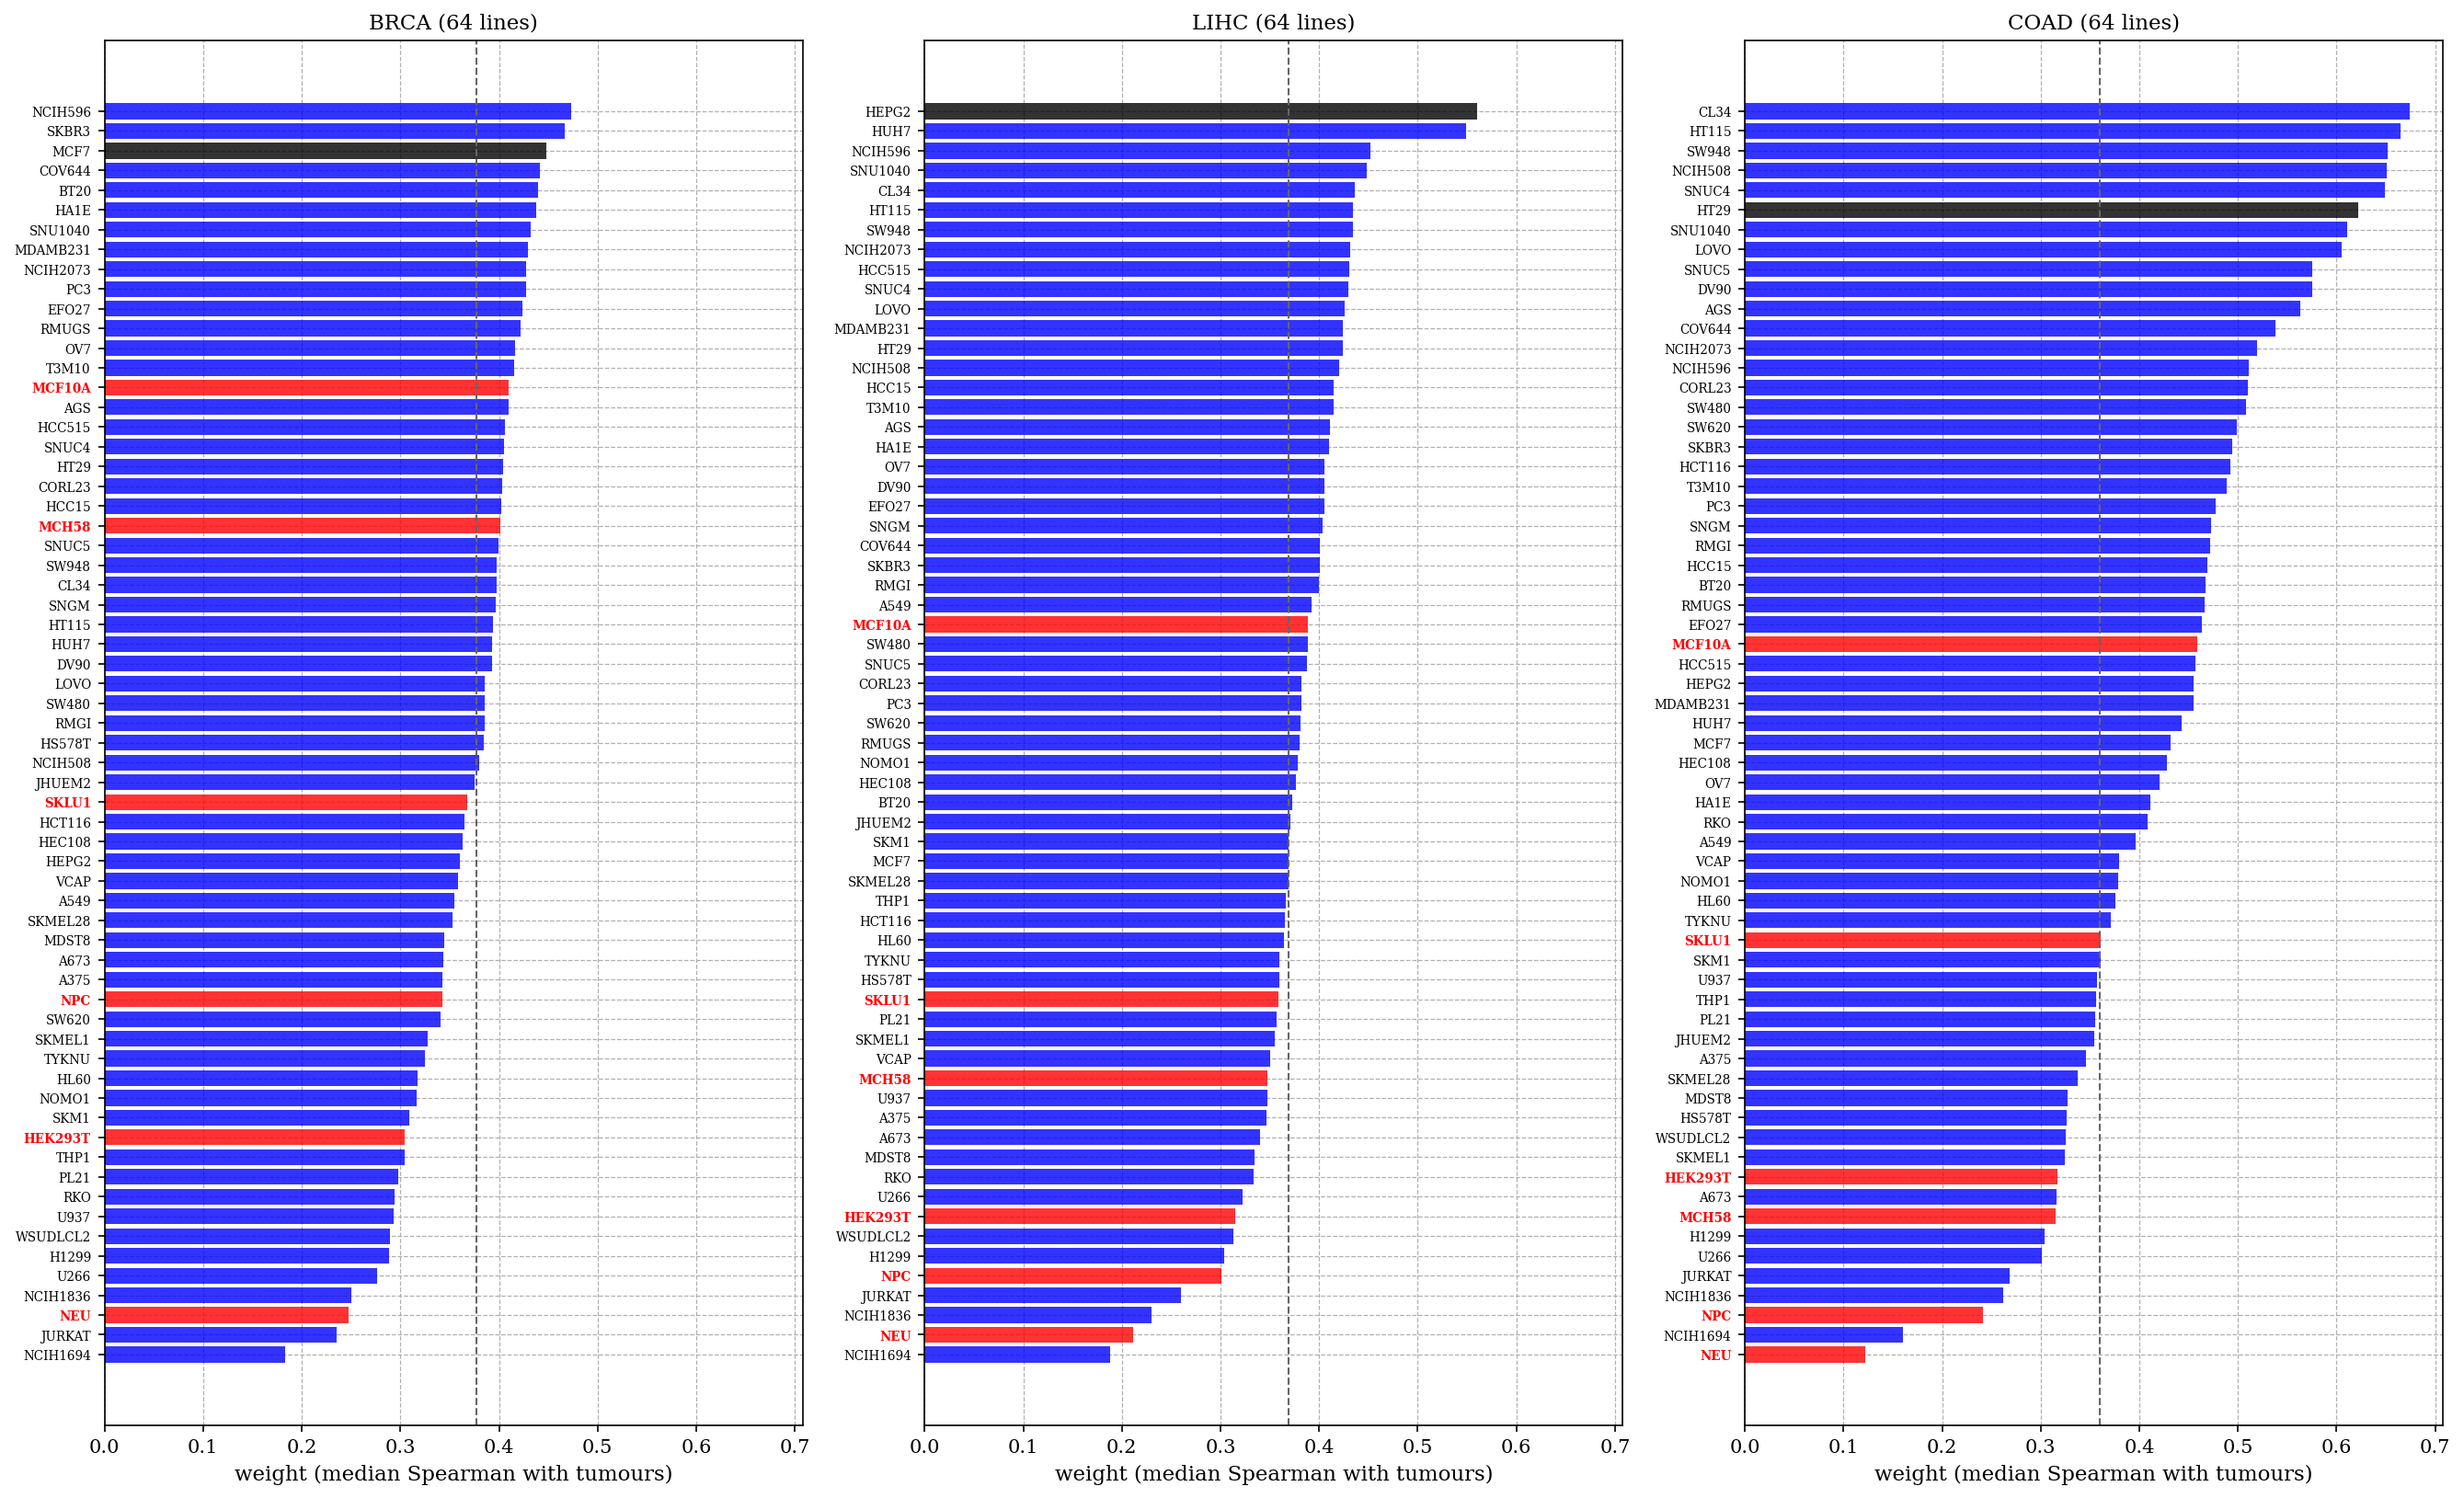

![weights](../imgs/binchen2017_validation/tcga_cell_line_weights_64.png)

**Figure 1.** Weight of the 64 weighted LINCS lines per cancer (median Spearman correlation with the primary tumours, dimensionless), sorted. Blue: DepMap lines; red and bold labels: lines weighted from HPA or GEO; black: the validation line. Dashed line: median weight of all CCLE lines with DepMap expression.

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 11), sharex=True)
for ax, c in zip(axes, CANCERS):
    d = w[w.cancer == c].sort_values('cor')
    col = [lfs_style.AFTER if s != 'DepMap' else ('k' if l == CANCERS[c] else lfs_style.BEFORE) for l, s in zip(d.lincs_cell_id, d.source)]
    ax.barh(range(len(d)), d['cor'], color=col, alpha=.8)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d['lincs_cell_id'], fontsize=6.5)
    for tl, s in zip(ax.get_yticklabels(), d.source):
        if s != 'DepMap': tl.set_color(lfs_style.AFTER); tl.set_fontweight('bold')
    allc = sim[sim.cancer == c]['median_cor']
    ax.axvline(allc.median(), color='0.4', ls='--', lw=1)
    ax.set_title(f'{c} ({len(d)} lines)', fontsize=11)
    ax.set_xlabel('weight (median Spearman with tumours)')
plt.tight_layout()
f = IMG / 'tcga_cell_line_weights_64.png'
fig.savefig(f, dpi=150); plt.close(fig)
display(Image(filename=str(f)))
display(Markdown(f"![weights]({REL}/{f.name})\n\n**Figure 1.** Weight of the 64 weighted LINCS lines per cancer (median Spearman correlation "
                 "with the primary tumours, dimensionless), sorted. Blue: DepMap lines; red and bold labels: lines weighted from HPA or GEO; "
                 "black: the validation line. Dashed line: median weight of all CCLE lines with DepMap expression."))

In [5]:
liv = w[w.lincs_cell_id.isin(['HEPG2', 'HUH7'])].pivot(index='lincs_cell_id', columns='cancer', values='cor')[list(CANCERS)]
rk = w.assign(rank=w.groupby('cancer')['cor'].rank(ascending=False)).pivot(index='lincs_cell_id', columns='cancer', values='rank')
display(Markdown("**Table 3.** Weight (dimensionless) and rank among the 64 weighted lines of the two liver cancer lines in LINCS: HepG2 "
                 "(hepatoblastoma-derived, LINCS annotation hepatocellular carcinoma) and HuH-7 (hepatocellular carcinoma). "
                 "HEP3B and HUH1 are not LINCS lines; PHH (primary hepatocytes) has no weight."))
md(pd.DataFrame({c: [f'{liv.loc[l, c]:.3f} (rank {int(rk.loc[l, c])})' for l in liv.index] for c in CANCERS}, index=liv.index))

**Table 3.** Weight (dimensionless) and rank among the 64 weighted lines of the two liver cancer lines in LINCS: HepG2 (hepatoblastoma-derived, LINCS annotation hepatocellular carcinoma) and HuH-7 (hepatocellular carcinoma). HEP3B and HUH1 are not LINCS lines; PHH (primary hepatocytes) has no weight.

| lincs_cell_id | BRCA | LIHC | COAD |
|---|---|---|---|
| HEPG2 | 0.361 (rank 39) | 0.560 (rank 1) | 0.455 (rank 30) |
| HUH7 | 0.393 (rank 28) | 0.549 (rank 2) | 0.443 (rank 32) |

## 4. Outputs

- `other_outputs/binchen2017_validation/tcga_cell_line_weights.tsv`: weights of the 64 lines (cancer, lincs_cell_id, cor, source).
- `tcga_cell_line_weights_ccle58.tsv`: the 58 DepMap weights alone.
- `tcga_external_cell_line_weights.tsv`, `tcga_external_cell_line_weights_table.tsv`, `tcga_hpa_depmap_paired_weights.tsv`.
- Figure: `imgs/binchen2017_validation/tcga_cell_line_weights_64.png`.
- Code: `src/validations/chembl/tcga_ccle_cell_line_weights.py` (run from `src/` with `PYTHONPATH=.`).